# Small Word Predictor (word embeddings from scratch)

Same architecture as the picture:

```
one-hot input word ──► hidden layer (linear, no bias) ──► one sum per vocab word (no bias) ──► SoftMax ──► P(next word)
   (V neurons)            (EMBED_DIM neurons)                    (V neurons)
```

| Layer | Neurons | Activation |
|---|---|---|
| Input | `V` = number of **unique** words in your text (one-hot: the current word is 1, all others 0) | none |
| Hidden | `EMBED_DIM` (2 in the picture) | **identity** (the straight-line boxes: output = input) |
| Output | `V` (one per unique word) | **SoftMax** across all outputs |

- **Loss:** cross-entropy between the SoftMax output and the real next word.
- **Training data:** every pair *(word, next word)* inside each sentence of your text.
- **Bonus:** the weights from one input word to the hidden neurons are that word's **embedding**. With `EMBED_DIM = 2` we can plot them: words used in similar places end up close together.

In [1]:
import re
import numpy as np
import matplotlib.pyplot as plt

## 1. Your text
Paste any text here. Sentences are split on `.`, `!`, `?` and new lines, so a prediction never jumps from the end of one sentence into the next.

In [2]:
TEXT = """
Troll2 is great!
Gymkata is great!
The cat sat on the mat.
The dog sat on the rug.
The cat chased the dog.
I love neural networks.
I love deep learning.
"""

## 2. Split into words, build the vocabulary and the training pairs

In [3]:
def tokenize(text):
    sentences = re.split(r"[.!?\n]+", text.lower())
    return [re.findall(r"[a-z0-9']+", s) for s in sentences if s.strip()]

sentences = tokenize(TEXT)

vocab = sorted({w for s in sentences for w in s})     # identical words appear only once
word_to_id = {w: i for i, w in enumerate(vocab)}
V = len(vocab)

# (current word, next word) pairs, only inside a sentence
pairs = [(s[i], s[i + 1]) for s in sentences for i in range(len(s) - 1)]

print(f"{len(sentences)} sentences, {sum(map(len, sentences))} words, {V} unique words, {len(pairs)} training pairs")
print("vocab:", vocab)
print("first pairs:", pairs[:6])

7 sentences, 31 words, 18 unique words, 24 training pairs
vocab: ['cat', 'chased', 'deep', 'dog', 'great', 'gymkata', 'i', 'is', 'learning', 'love', 'mat', 'networks', 'neural', 'on', 'rug', 'sat', 'the', 'troll2']
first pairs: [('troll2', 'is'), ('is', 'great'), ('gymkata', 'is'), ('is', 'great'), ('the', 'cat'), ('cat', 'sat')]


In [4]:
def one_hot(ids, size):
    m = np.zeros((len(ids), size))
    m[np.arange(len(ids)), ids] = 1
    return m

X = one_hot([word_to_id[a] for a, _ in pairs], V)    # (n, V) inputs
Y = one_hot([word_to_id[b] for _, b in pairs], V)    # (n, V) targets
print("X:", X.shape, " Y:", Y.shape)

X: (24, 18)  Y: (24, 18)


## 3. The network

In [5]:
EMBED_DIM = 2      # hidden neurons (2 = same as the picture, and lets us plot the embeddings)

W1 = None   # (V, EMBED_DIM): input -> hidden weights  (row i = embedding of word i)
W2 = None   # (EMBED_DIM, V): hidden -> output weights

def init():
    global W1, W2
    W1 = np.random.uniform(-0.5, 0.5, (V, EMBED_DIM))
    W2 = np.random.uniform(-0.5, 0.5, (EMBED_DIM, V))

In [6]:
def softmax(z):
    z = z - z.max(axis=1, keepdims=True)    # subtract the max so exp() never overflows
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def cal_loss(Y, P):
    # cross-entropy: -log(probability given to the correct next word), averaged
    return -np.mean(np.log(np.sum(Y * P, axis=1) + 1e-12))

In [7]:
def forward_propagation(X):
    H = X @ W1             # hidden layer, identity activation: just the weighted sums
    Z = H @ W2             # one sum per vocab word
    P = softmax(Z)         # probabilities for the next word
    return H, P

## 4. Backpropagation (chain rule)

- SoftMax + cross-entropy: `dL/dZ = P - Y`
- `Z = H @ W2` → `dL/dW2 = Hᵀ @ dZ`, and `dL/dH = dZ @ W2ᵀ`
- `H = X @ W1` → `dL/dW1 = Xᵀ @ dH` (identity activation, so its derivative is 1)

In [8]:
def back_propagation(X, Y, H, P):
    global W1, W2
    n = len(X)
    dZ = (P - Y) / n
    dW2 = H.T @ dZ
    dH = dZ @ W2.T
    dW1 = X.T @ dH
    W1 -= lr * dW1
    W2 -= lr * dW2

In [9]:
def fit(X, Y):
    init()
    loss = []
    for i in range(n_iters):
        H, P = forward_propagation(X)
        loss.append(cal_loss(Y, P))
        back_propagation(X, Y, H, P)
    return loss

## 5. Train

final loss: 0.4512


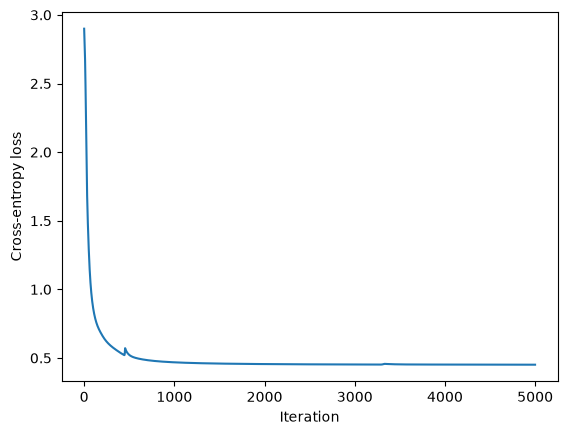

In [10]:
lr = 1.0
n_iters = 5000

loss = fit(X, Y)
print("final loss:", round(loss[-1], 4))

plt.plot(loss)
plt.xlabel("Iteration")
plt.ylabel("Cross-entropy loss")
plt.show()

## 6. Look at the word embeddings
Each dot is one word, placed at its two input→hidden weights. Words that are followed by the same words drift together.

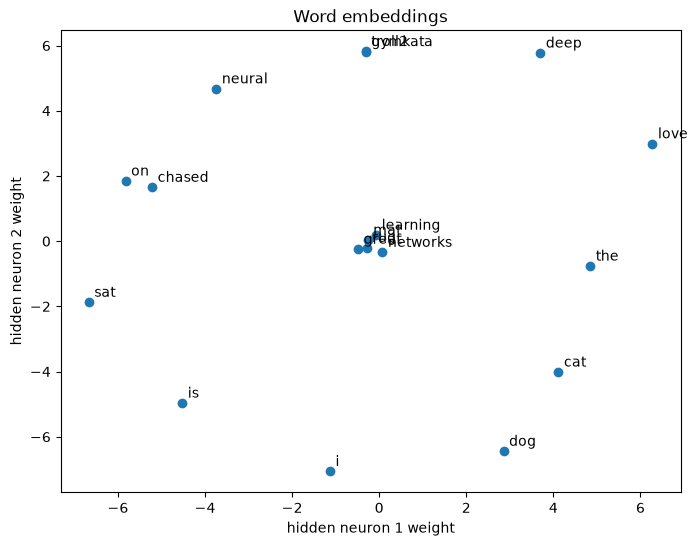

In [11]:
if EMBED_DIM == 2:
    plt.figure(figsize=(8, 6))
    plt.scatter(W1[:, 0], W1[:, 1])
    for w, (a, b) in zip(vocab, W1):
        plt.annotate(w, (a, b), textcoords="offset points", xytext=(4, 4))
    plt.xlabel("hidden neuron 1 weight")
    plt.ylabel("hidden neuron 2 weight")
    plt.title("Word embeddings")
    plt.show()
else:
    print("Set EMBED_DIM = 2 to plot the embeddings.")

## 7. Predict

In [12]:
def predict_next(word, top_k=3):
    word = word.lower()
    if word not in word_to_id:
        raise ValueError(f"'{word}' is not in the vocabulary: {vocab}")
    _, P = forward_propagation(one_hot([word_to_id[word]], V))
    best = np.argsort(P[0])[::-1][:top_k]
    return [(vocab[i], round(float(P[0, i]), 3)) for i in best]

def generate(start, n_words=5, sample=False):
    """Keep feeding the predicted word back in. sample=True picks randomly by probability."""
    words = [start.lower()]
    for _ in range(n_words):
        _, P = forward_propagation(one_hot([word_to_id[words[-1]]], V))
        p = P[0]
        nxt = np.random.choice(V, p=p) if sample else int(np.argmax(p))
        words.append(vocab[nxt])
    return " ".join(words)

In [13]:
for w in ["troll2", "gymkata", "is", "the", "sat", "love"]:
    print(f"{w:8s} -> {predict_next(w)}")

print()
print(generate("troll2", 3))
print(generate("the", 5))
print(generate("i", 3, sample=True))

troll2   -> [('is', 0.998), ('learning', 0.001), ('networks', 0.001)]
gymkata  -> [('is', 0.998), ('learning', 0.001), ('networks', 0.001)]
is       -> [('great', 0.998), ('love', 0.001), ('on', 0.001)]
the      -> [('cat', 0.367), ('dog', 0.299), ('mat', 0.166)]
sat      -> [('on', 0.999), ('great', 0.001), ('the', 0.001)]
love     -> [('deep', 0.56), ('neural', 0.438), ('learning', 0.001)]

troll2 is great on
the cat sat on the cat
i love neural networks


In [14]:
print(generate("i", 10))

i love deep learning is great on the cat sat on
